In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, roc_curve, roc_auc_score, average_precision_score,
                             precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
%matplotlib inline


In [9]:

def add_features(df):
    df = df.copy()
    df['Weekend'] = df['Weekend'].astype(int)

    df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
    df['TotalTime'] = (df['Administrative_Duration'] + df['Informational_Duration']
                       + df['ProductRelated_Duration'])


    for new_col, dur, cnt in [
        ('Adm_time_per_page', 'Administrative_Duration', 'Administrative'),
        ('Info_time_per_page', 'Informational_Duration', 'Informational'),
        ('Pr_time_per_page', 'ProductRelated_Duration', 'ProductRelated'),
    ]:
        df[new_col] = (df[dur] / df[cnt].where(df[cnt] > 0)).fillna(0)
    return df

In [10]:
# Load cleaned data (raw columns فقط - الـ encoding والـ features جوه الـ Pipeline)
train_data = pd.read_csv('cleaned_data.csv')
print("dataset shape:", train_data.shape)
print(train_data['Revenue'].value_counts(normalize=True).round(3))



dataset shape: (999990, 18)
Revenue
0    0.845
1    0.155
Name: proportion, dtype: float64


In [11]:
X = train_data.drop(columns='Revenue')
y = train_data['Revenue']

# الـ Validation بنختار عليه الـ Threshold والموديل، والـ Test بنقيس عليه مرة واحدة بس في الآخر
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=1/9, random_state=42, stratify=y_temp)
print(X_train.shape, X_val.shape, X_test.shape)

(799992, 17) (99999, 17) (99999, 17)


In [12]:
cat_cols = ['Month', 'VisitorType']
num_cols = [c for c in add_features(X_train.head()).columns if c not in cat_cols]


def make_preprocessor(scale):
    return Pipeline([
        ('features', FunctionTransformer(add_features)),
        ('encode', ColumnTransformer([
            ('num', StandardScaler() if scale else 'passthrough', num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ])),
    ])


def best_threshold(y_true, probs):
    p, r, t = precision_recall_curve(y_true, probs)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

In [13]:
trained_pipelines = {}

# 1) Logistic Regression
trained_pipelines['Logistic Regression'] = Pipeline([
    ('prep', make_preprocessor(scale=True)),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
]).fit(X_train, y_train)

# 2) Random Forest
trained_pipelines['Random Forest'] = Pipeline([
    ('prep', make_preprocessor(scale=False)),
    ('model', RandomForestClassifier(n_estimators=150, max_depth=16, min_samples_leaf=10,
                                     n_jobs=-1, random_state=42)),
]).fit(X_train, y_train)

In [14]:
# 3) XGBoost
xgb_params = {
    'max_depth': 6,
    'tree_method': 'hist',
    'learning_rate': 0.019808197105717858,
    'subsample': 0.6644241250807604,
    'colsample_bytree': 0.7354821603782602,
    'gamma': 0.7403752522353874,
    'min_child_weight': 0.17127719592435836,
    'reg_alpha': 1.688819998615072e-08,
    'reg_lambda': 0.10435422811684221,
    'random_state': 42,
}

xgb_prep = make_preprocessor(scale=False)
X_train_t = xgb_prep.fit_transform(X_train)
X_val_t = xgb_prep.transform(X_val)

xgb_clf = XGBClassifier(**xgb_params, n_estimators=1500, early_stopping_rounds=50,
                        eval_metric='auc', n_jobs=-1)
xgb_clf.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], verbose=False)

trained_pipelines['XGBoost'] = Pipeline([('prep', xgb_prep), ('model', xgb_clf)])

In [15]:
# Evaluation: كل الموديلات بنفس الطريقة (Threshold من الـ Validation، النتايج على الـ Test)
baseline_acc = 1 - y_test.mean()
print(f"Baseline (always predict 'No purchase') accuracy = {baseline_acc:.4f}\n")

rows, thresholds = [], {}
for name, pipe in trained_pipelines.items():
    val_probs = pipe.predict_proba(X_val)[:, 1]
    thr = best_threshold(y_val, val_probs)
    thresholds[name] = thr

    test_probs = pipe.predict_proba(X_test)[:, 1]
    test_pred = (test_probs >= thr).astype(int)
    rows.append({
        'model': name, 'threshold': thr,
        'val_f1': f1_score(y_val, (val_probs >= thr).astype(int)),
        'test_accuracy': accuracy_score(y_test, test_pred),
        'test_precision': precision_score(y_test, test_pred),
        'test_recall': recall_score(y_test, test_pred),
        'test_f1': f1_score(y_test, test_pred),
        'test_roc_auc': roc_auc_score(y_test, test_probs),
        'test_pr_auc': average_precision_score(y_test, test_probs),
    })

results = pd.DataFrame(rows).set_index('model').round(4)
display(results)

best_model_name = results['val_f1'].idxmax()
best_pipeline = trained_pipelines[best_model_name]
best_threshold_value = thresholds[best_model_name]
print(f"\nBest model: {best_model_name} | threshold = {best_threshold_value:.3f}")

Baseline (always predict 'No purchase') accuracy = 0.8453



,threshold,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
model,,,,,,,,
Logistic Regression,0.4067,0.7041,0.9181,0.8001,0.6274,0.7033,0.9176,0.7929
Random Forest,0.3197,0.7921,0.9388,0.8307,0.7591,0.7933,0.9639,0.8877
XGBoost,0.3888,0.8091,0.9433,0.8441,0.7773,0.8093,0.9704,0.9028



Best model: XGBoost | threshold = 0.389


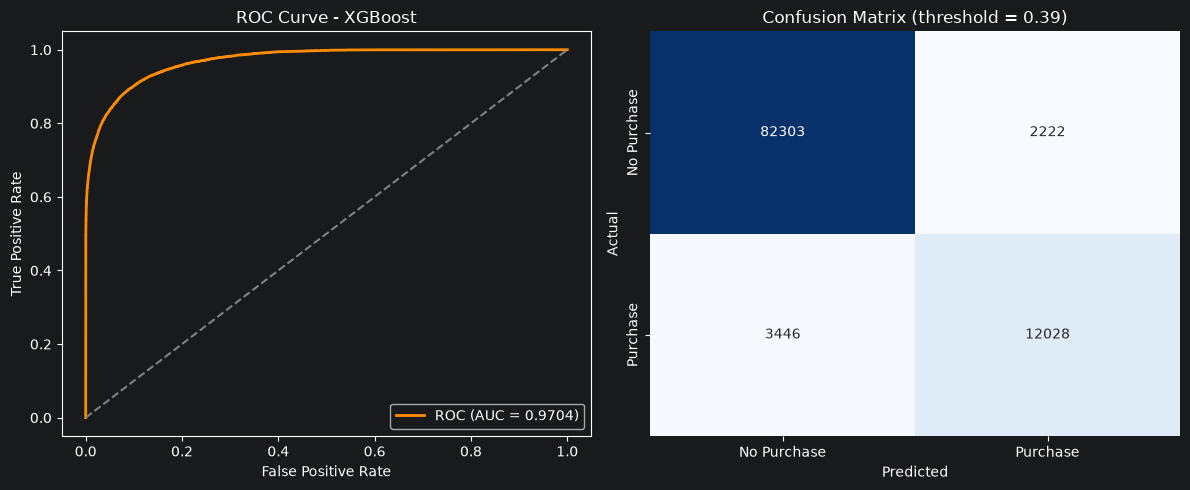

              precision    recall  f1-score   support

 No Purchase       0.96      0.97      0.97     84525
    Purchase       0.84      0.78      0.81     15474

    accuracy                           0.94     99999
   macro avg       0.90      0.88      0.89     99999
weighted avg       0.94      0.94      0.94     99999



In [16]:
# ROC Curve & Confusion Matrix (Best model, Test set)
y_probs = best_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_probs >= best_threshold_value).astype(int)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
fpr, tpr, _ = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc_score(y_test, y_probs):.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve - {best_model_name}')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Purchase', 'Purchase'], yticklabels=['No Purchase', 'Purchase'])
plt.title(f'Confusion Matrix (threshold = {best_threshold_value:.2f})')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=['No Purchase', 'Purchase']))

In [17]:
# Save the final model for the UI

bundle = {
    'pipeline': best_pipeline,
    'threshold': best_threshold_value,
    'model_name': best_model_name,
    'raw_columns': list(X_train.columns),
}
with open('pipe.pkl', 'wb') as f:
    pickle.dump(bundle, f)
print("Saved 'pipe.pkl'")



Saved 'pipe.pkl'
